https://scikit-learn.org/stable/index.html
https://pysteps.readthedocs.io/en/stable/index.html
https://courses.grainger.illinois.edu/bioe205/sp2023/lectures/lec09/
https://matplotlib.org/

# 02_features_classification
---

## Imports

In [33]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier


In [34]:
ROOT = Path.cwd().parent          # remonte de notebooks/ vers Détecteur AI/
dossier_train_real = ROOT / "data" / "cifake" / "train" / "REAL"
dossier_train_fake = ROOT / "data" / "cifake" / "train" / "FAKE"
dossier_test_real = ROOT / "data" / "cifake" / "test" / "REAL"
dossier_test_fake = ROOT / "data" / "cifake" / "test" / "FAKE"

### Images du dossier: train

In [35]:
taille_utilisation = 50000  # Nombre d'images à utiliser pour l'entraînement
fichiers_train_real = list(dossier_train_real.glob("*.jpg"))[:taille_utilisation]
fichiers_train_fake = list(dossier_train_fake.glob("*.jpg"))[:taille_utilisation]

# Les listes vides, AVANT les boucles
x_train = []
y_train = []

# Boucle sur les images REAL -> etiquette 0
for chemin in fichiers_train_real:
    img = Image.open(chemin).convert("L")
    tableau = np.asarray(img)
    x_train.append(tableau)
    y_train.append(0)

# Boucle sur les images FAKE -> etiquette 1
for chemin in fichiers_train_fake:
    img = Image.open(chemin).convert("L")
    tableau = np.asarray(img)
    x_train.append(tableau)
    y_train.append(1)

# Transformer les listes en tableaux NumPy
x_train = np.array(x_train)
y_train = np.array(y_train)

# Verification
print("X :", x_train.shape, "| y :", np.bincount(y_train))

X : (100000, 32, 32) | y : [50000 50000]


### Images du dossier: test

In [36]:
fichiers_test_real = list(dossier_test_real.glob("*.jpg"))
fichiers_test_fake = list(dossier_test_fake.glob("*.jpg"))

# Les listes vides, AVANT les boucles
x_test = []
y_test = []

# Boucle sur les images REAL -> etiquette 0
for chemin in fichiers_test_real:
    img = Image.open(chemin).convert("L")
    tableau = np.asarray(img)
    x_test.append(tableau)
    y_test.append(0)

# Boucle sur les images FAKE -> etiquette 1
for chemin in fichiers_test_fake:
    img = Image.open(chemin).convert("L")
    tableau = np.asarray(img)
    x_test.append(tableau)
    y_test.append(1)

# Transformer les listes en tableaux NumPy
x_test = np.array(x_test)
y_test = np.array(y_test)

# Verification
print("X :", x_test.shape, "| y :", np.bincount(y_test))

X : (20000, 32, 32) | y : [10000 10000]


### train-test-split:

In [37]:

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train,
    test_size=0.2,       # 20 % du train part en validation
    random_state=42,
    stratify=y_train
)

print(x_train.shape, y_train.shape)

(80000, 32, 32) (80000,)


## Analyse

### distance Radial

In [38]:
def rapsd(image):
    f = np.fft.fftshift(np.fft.fft2(image))
    energie = np.abs(f) ** 2
    h, w = image.shape
    cy, cx = h // 2, w // 2 #pour avoir le numero d'un pixel precis, on divise la hauteur et la largeur par 2
    y, x = np.indices((h, w)) #donne la ligne et la colonne pourchaque pixels
    rayon = np.sqrt((x - cx)**2 + (y - cy)**2).astype(int)
    somme = np.bincount(rayon.ravel(), weights=energie.ravel())
    nombre = np.bincount(rayon.ravel())
    return somme / nombre

In [39]:
profil = rapsd(x_train[0])
print(profil.shape)

(23,)


In [40]:
features_train = []
for image in x_train:
    features_train.append(rapsd(image))
features_train = np.array(features_train)

features_val = []
for image in x_val:
    features_val.append(rapsd(image))
features_val = np.array(features_val)

features_test = []
for image in x_test:
    features_test.append(rapsd(image))
features_test = np.array(features_test)

print("features_train :", features_train.shape)
print("features_test  :", features_val.shape)
print("features_test  :", features_test.shape)

features_train : (80000, 23)
features_test  : (20000, 23)
features_test  : (20000, 23)


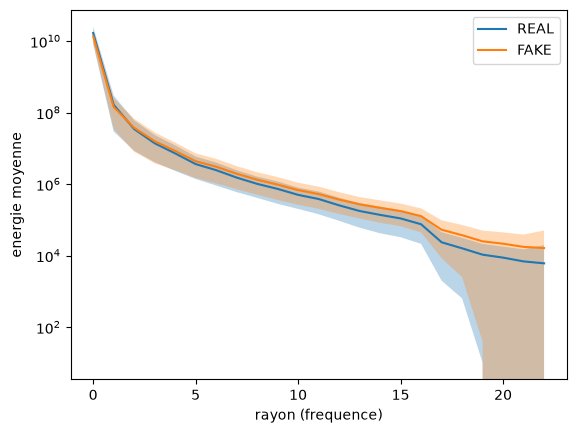

In [ ]:
# Moyennes (comme avant)
real = features_train[y_train == 0]
fake = features_train[y_train == 1]

moy_real = real.mean(axis=0)
moy_fake = fake.mean(axis=0)

# Ecarts-types (la nouveaute)
std_real = real.std(axis=0)
std_fake = fake.std(axis=0)

x = np.arange(len(moy_real))   # les numeros d'anneau, pour l'axe x

plt.semilogy(x, moy_real, label="REAL")
plt.fill_between(x, moy_real - std_real, moy_real + std_real, alpha=0.3)

plt.semilogy(x, moy_fake, label="FAKE")
plt.fill_between(x, moy_fake - std_fake, moy_fake + std_fake, alpha=0.3)

plt.xlabel("rayon (frequence)")
plt.ylabel("energie moyenne")
plt.legend()
plt.show()

## Modèle

In [42]:
scaler = StandardScaler()
features_train_scaled = scaler.fit_transform(features_train)
features_val_scaled = scaler.transform(features_val)

### Regression Logistique

In [43]:
lr = LogisticRegression(max_iter=1000)
lr.fit(features_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [44]:
pred_val = lr.predict(features_val_scaled)
score = accuracy_score(y_val, pred_val)
print("Precision sur le test :", score)

Precision sur le test : 0.73795


In [45]:
pred_val = lr.predict(features_val_scaled)
cm = confusion_matrix(y_val, pred_val)
print(cm)

[[7983 2017]
 [3224 6776]]


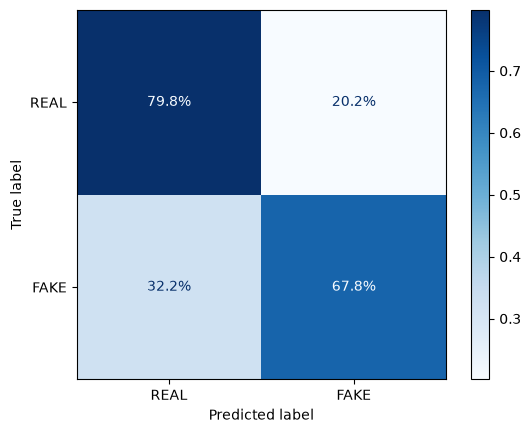

In [46]:
ConfusionMatrixDisplay.from_estimator(
    lr,
    features_val_scaled,
    y_val,
    display_labels=["REAL", "FAKE"],
    normalize="true",      # pourcentage par ligne (par vraie classe)
    values_format=".1%",    # affiche en pourcentage avec 1 decimale
    cmap=plt.cm.Blues,

)
plt.show()

In [47]:
print(classification_report(y_val, pred_val, target_names=["REAL", "FAKE"]))

              precision    recall  f1-score   support

        REAL       0.71      0.80      0.75     10000
        FAKE       0.77      0.68      0.72     10000

    accuracy                           0.74     20000
   macro avg       0.74      0.74      0.74     20000
weighted avg       0.74      0.74      0.74     20000



### Random forest:

In [48]:
# Echantillon pour la recherche
taille_reglage = 8000
idx = np.random.RandomState(42).permutation(len(features_train_scaled))[:taille_reglage]
features_sample = features_train_scaled[idx]
y_sample = y_train[idx]

In [49]:
grille = {
    "n_estimators": [100, 200],
    "max_depth": [20, 30]
}

rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    grille,
    cv=3,              # validation croisee en n morceaux
    scoring="accuracy",
    n_jobs=-1
)
rf.fit(features_train_scaled, y_train)

print("Meilleurs reglages :", rf.best_params_)
print("Meilleur score (validation croisee) :", rf.best_score_)

Meilleurs reglages : {'max_depth': 30, 'n_estimators': 200}
Meilleur score (validation croisee) : 0.7925125022789387


In [50]:
pred_val_rf = rf.best_estimator_.predict(features_val_scaled)
score_rf = accuracy_score(y_val, pred_val_rf)
print("Precision validation (Random Forest) :", score_rf)

Precision validation (Random Forest) : 0.79175


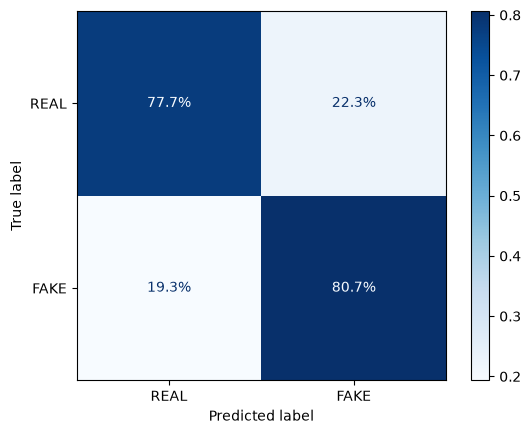

In [51]:
ConfusionMatrixDisplay.from_estimator(
    rf,
    features_val_scaled,
    y_val,
    display_labels=["REAL", "FAKE"],
    normalize="true",      # pourcentage par ligne (par vraie classe)
    values_format=".1%",    # affiche en pourcentage avec 1 decimale
    cmap=plt.cm.Blues,
)
plt.show()

### XGBoost

In [52]:
# Echantillon pour la recherche
taille_reglage = 8000
idx = np.random.RandomState(42).permutation(len(features_train_scaled))[:taille_reglage]
features_sample = features_train_scaled[idx]
y_sample = y_train[idx]

In [54]:
grille = {
    "n_estimators": [100, 200],
    "max_depth": [5, 7]
}
xgb = GridSearchCV(
    XGBClassifier(random_state=42),
    grille,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
xgb.fit(features_train_scaled, y_train)

pred_val_xgb = xgb.predict(features_val_scaled)
score_xgb = accuracy_score(y_val, pred_val_xgb)
print("XGBoost sur validation :", score_xgb)

XGBoost sur validation : 0.7921


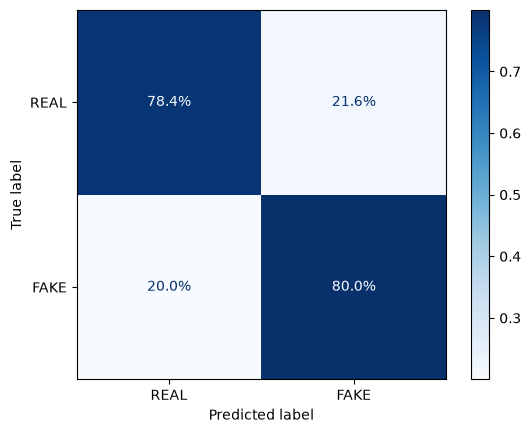

In [55]:
ConfusionMatrixDisplay.from_estimator(
    xgb,
    features_val_scaled,
    y_val,
    display_labels=["REAL", "FAKE"],
    normalize="true",      # pourcentage par ligne (par vraie classe)
    values_format=".1%",    # affiche en pourcentage avec 1 decimale
    cmap=plt.cm.Blues,

)
plt.show()

## Test

Score FINAL sur le test officiel : 0.7966
              precision    recall  f1-score   support

        REAL       0.80      0.79      0.80     10000
        FAKE       0.79      0.80      0.80     10000

    accuracy                           0.80     20000
   macro avg       0.80      0.80      0.80     20000
weighted avg       0.80      0.80      0.80     20000



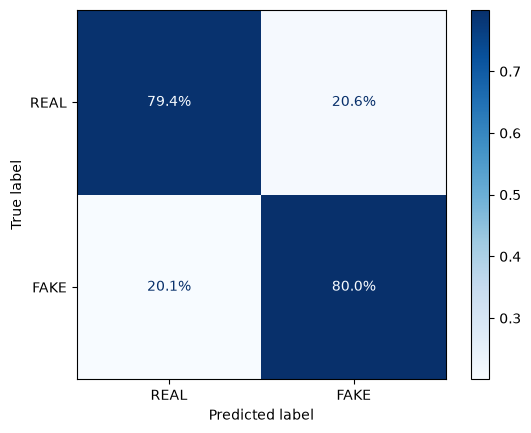

In [56]:
# 1. Mettre le test officiel a l'echelle (meme scaler)
features_test_scaled = scaler.transform(features_test)

# 2. Prediction finale avec XGBoost (le meilleur)
pred_test = xgb.predict(features_test_scaled)

# 3. Score final
score_test = accuracy_score(y_test, pred_test)
print("Score FINAL sur le test officiel :", score_test)

# 4. Detail
print(classification_report(y_test, pred_test, target_names=["REAL", "FAKE"]))

ConfusionMatrixDisplay.from_estimator(
    xgb, features_test_scaled, y_test,
    display_labels=["REAL", "FAKE"],
    normalize="true", values_format=".1%", cmap=plt.cm.Blues,
)
plt.show()